# MS/MS prediction with GLACIER

Predict the fragment masses and intensities of a molecule under specified acquisition conditions.

GLACIER takes the molecular structure, adduct, collision energy and instrument. Its fragment and intensity components produce a numerical MS/MS peak list.

This tutorial loads the saved predictions, explains the input/output fields and evaluates the results. Use the final command to run the model on a new dataset.

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('ms.forward.glacier')
print('Task:', evidence['task'])
print('Examples:', len(evidence['examples']))

Task: ms.forward.glacier
Examples: 3


## Inputs and outputs

| Field | Meaning |
| --- | --- |
| `smiles / adduct` | Molecular structure and ion/adduct, e.g. the actual [M+H]+ or [M+Na]+ in the record. |
| `collision_energy / instrument` | Collision energy and instrument settings supported by the model. |
| `precursor_mz` | Recorded precursor m/z; input conventions follow the author interface. |

| Field | Meaning |
| --- | --- |
| `predicted_peaks` | Pairs of m/z and relative intensity; figures retain the top 100 predicted peaks. |
| `similarity` | Cosine/entropy similarity to all observed reference peaks, with skipped records counted. |

Inspect the example records below. Long arrays show their length and first values; the downloadable JSON contains the complete arrays.

In [2]:
for example in evidence['examples'][:3]:
    print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "input": {
    "smiles": "CC(C)(C)c1ccc(C(=O)CCCN2CCC(OC(c3ccccc3)c3ccccc3)CC2)cc1",
    "adduct": "[M+H]+",
    "collision_energy": "40.0",
    "instrument": "QTOF",
    "precursor_mz": 470.3054
  },
  "sample_id": "MassSpecGymID0028855",
  "output": {
    "predicted_peaks_top100": {
      "length": 100,
      "first_values": [
        [
          55.05422667404919,
          0.0020994183141738176
        ],
        [
          57.069876707999995,
          0.008048541843891144
        ],
        [
          70.065125676,
          0.0050727734342217445
        ],
        [
          82.06512569102459,
          0.0035072911996394396
        ],
        [
          84.0807757249754,
          0.006053834222257137
        ],
        [
          84.08077573999999,
          0.004439487587660551
        ],
        [
          84.08077573999999,
          0.019418761134147644
        ],
        [
          91.05422683833227,
          0.0017777407774701715
        ]
      ]
    }
  },


## Evaluate the predictions

Compare the predicted and measured spectra using cosine and entropy similarity.

The table gives the dataset and metric for each run. The following calculation recomputes summary values from the plotted predictions.

In [3]:
display(Markdown(results_table(evidence, True)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| recorded evaluation | recorded model | cosine_similarity | 0.485717 |
| recorded evaluation | recorded model | entropy_similarity | 0.41328 |


{
  "scope": "Saved model outputs are shown directly; aggregate metrics are in the run table.",
  "recorded_runs": 1,
  "real_examples": 3
}


## Visualize the result

Measured and predicted MS/MS spectra.

Compare the prediction with the reference and inspect the returned structures or peak positions. The plot is generated directly from the records loaded above.

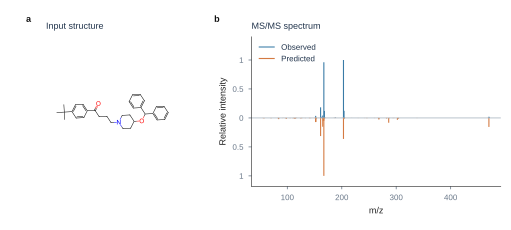

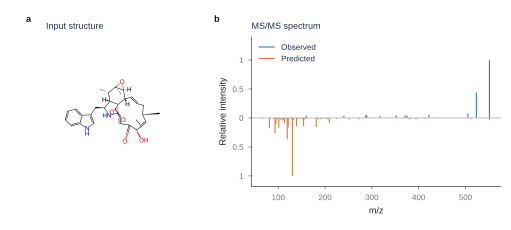

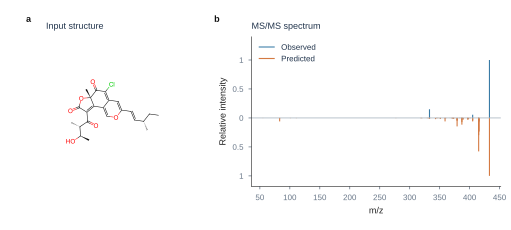

In [4]:
import matplotlib.pyplot as plt
for example_index in range(3):
    figure = render('ms.forward.glacier', evidence, example_index=example_index)
    image = io.StringIO()
    figure.savefig(image, format='svg', metadata={'Date': None})
    display(SVG(image.getvalue()))
    plt.close(figure)

## Run the model

Configure the runtime and weights following the task guide. Select this task in the benchmark runner to evaluate your dataset.

```bash
python -m openmolspec_bench run --workspace /path/to/OpenMolSpec \
  --tasks ms.forward.glacier --limit 8 --output results/ms-forward-glacier.json
```

[Task](../tasks/ms-forward-glacier.md) · [Quick start](../quickstart.md)



## References

- Wang, R.-X., Wang, R. & Coley, C. W. GLACIER: Rethinking Mass Spectrum Prediction as an Object Detection Problem. NeurIPS 2026. arXiv:2606.29161 (2026). [Source](https://arxiv.org/abs/2606.29161)
- Bushuiev, R., Bushuiev, A., de Jonge, N. F., Young, A., et al. MassSpecGym: A benchmark for the discovery and identification of molecules. Advances in Neural Information Processing Systems 37, Datasets and Benchmarks Track (2024). arXiv:2410.23326. [Source](https://arxiv.org/abs/2410.23326)
